### Mount Google Drive
By mounting Google Drive, you can easily read and write files directly from your personal storage.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Step 1: Locate and Inspect the Dataset
Let's write a script to search `/content/drive/MyDrive/` for directories, zip files, or files named `archive` or related to helmet detection, and inspect their structure.

In [2]:
import os
import glob

# Look for any matching archives, directories or zip files
search_root = '/content/drive/MyDrive'
print(f"Searching within {search_root}...")

all_items = glob.glob(os.path.join(search_root, '**'), recursive=True)
possible_paths = [p for p in all_items if 'archive' in p.lower() or 'helmet' in p.lower()]

if possible_paths:
    print("\nFound matching paths:")
    for idx, path in enumerate(possible_paths[:30]):
        print(f"{idx+1}. {path} ({'Directory' if os.path.isdir(path) else 'File'})")
else:
    print("\nNo direct matches found. Showing top-level directories under MyDrive instead:")
    for item in os.listdir(search_root):
        full_p = os.path.join(search_root, item)
        print(f" - {item} ({'Directory' if os.path.isdir(full_p) else 'File'})")

Searching within /content/drive/MyDrive...

Found matching paths:
1. /content/drive/MyDrive/Decision Tree/archive (Directory)
2. /content/drive/MyDrive/Decision Tree/archive/drug200.csv (File)
3. /content/drive/MyDrive/archive(2) (Directory)
4. /content/drive/MyDrive/archive(2)/train_transformed (Directory)
5. /content/drive/MyDrive/archive(2)/train_transformed/dog120.jpg (File)
6. /content/drive/MyDrive/archive(2)/train_transformed/dog388.jpg (File)
7. /content/drive/MyDrive/archive(2)/train_transformed/dog49.jpg (File)
8. /content/drive/MyDrive/archive(2)/train_transformed/cat788.jpg (File)
9. /content/drive/MyDrive/archive(2)/train_transformed/dog47.jpg (File)
10. /content/drive/MyDrive/archive(2)/train_transformed/dog354.jpg (File)
11. /content/drive/MyDrive/archive(2)/train_transformed/dog295.jpg (File)
12. /content/drive/MyDrive/archive(2)/train_transformed/cat820.jpg (File)
13. /content/drive/MyDrive/archive(2)/train_transformed/cat976.jpg (File)
14. /content/drive/MyDrive/archi

### Step 1b: Deep Search for Helmet Dataset files or Archives
Let's search for any `.zip`, `.tar.gz`, `.rar` files or folder structures on Google Drive containing keywords like `helmet`, `safety`, `hardhat`, or `dataset` to locate the source archive.

In [3]:
import os
import glob

search_root = '/content/drive/MyDrive'
keywords = ['helmet', 'hardhat', 'safety', 'archive', 'dataset']
extensions = ['*.zip', '*.tar.gz', '*.rar', '*.7z', '*.tar']

found_archives = []
for ext in extensions:
    found_archives.extend(glob.glob(os.path.join(search_root, '**', ext), recursive=True))

print("--- Found Archive Files ---")
for idx, archive in enumerate(found_archives):
    print(f"{idx+1}. {archive}")

print("\n--- Found Folders with Target Keywords ---")
found_folders = []
for root, dirs, files in os.walk(search_root):
    for d in dirs:
        if any(kw in d.lower() for kw in keywords):
            path = os.path.join(root, d)
            found_folders.append(path)
            if len(found_folders) <= 20:
                print(f"- {path}")

--- Found Archive Files ---

--- Found Folders with Target Keywords ---
- /content/drive/MyDrive/datasetttttt
- /content/drive/MyDrive/archive(2)
- /content/drive/MyDrive/archive
- /content/drive/MyDrive/Decision Tree/archive


### Step 1c: Inspect contents of `/content/drive/MyDrive/archive` and `/content/drive/MyDrive/datasetttttt`

In [4]:
import os

def inspect_dir(path, max_items=15):
    if os.path.exists(path):
        items = os.listdir(path)
        print(f"\n--- {path} (Total items: {len(items)}) ---")
        for item in items[:max_items]:
            item_path = os.path.join(path, item)
            if os.path.isdir(item_path):
                print(f"  [DIR]  {item} (contains {len(os.listdir(item_path))} items)")
            else:
                print(f"  [FILE] {item}")
    else:
        print(f"\nPath {path} does not exist.")

inspect_dir('/content/drive/MyDrive/archive')
inspect_dir('/content/drive/MyDrive/datasetttttt')


--- /content/drive/MyDrive/archive (Total items: 3) ---
  [DIR]  annotations (contains 764 items)
  [DIR]  images (contains 764 items)
  [DIR]  .ipynb_checkpoints (contains 0 items)

--- /content/drive/MyDrive/datasetttttt (Total items: 2) ---
  [FILE] drug200.csv
  [FILE] WA_Fn-UseC_-Telco-Customer-Churn.csv


### Step 1d: Inspect Annotation Formats, File Extensions, and Unique Classes
We will examine the file extensions of images and annotations, and parse a sample annotation file to detect its format and identify all class names automatically.

In [5]:
import os
import xml.etree.ElementTree as ET
from collections import Counter

images_dir = '/content/drive/MyDrive/archive/images'
annotations_dir = '/content/drive/MyDrive/archive/annotations'

image_files = sorted(os.listdir(images_dir))
annotation_files = sorted(os.listdir(annotations_dir))

print(f"First 5 images: {image_files[:5]}")
print(f"First 5 annotations: {annotation_files[:5]}")

# Let's inspect the first annotation file content to see the format
if annotation_files:
    sample_ann_path = os.path.join(annotations_dir, annotation_files[0])
    print(f"\n--- Sample Annotation File Name: {annotation_files[0]} ---")

    # Check file extension to read correctly
    _, ext = os.path.splitext(sample_ann_path)
    if ext.lower() == '.xml':
        print("Detected XML format. Reading first 20 lines:")
        with open(sample_ann_path, 'r') as f:
            print("".join(f.readlines()[:25]))

        # Let's count unique class occurrences from all XML annotations
        classes_counter = Counter()
        for ann in annotation_files:
            if ann.endswith('.xml'):
                tree = ET.parse(os.path.join(annotations_dir, ann))
                root = tree.getroot()
                for obj in root.findall('object'):
                    name = obj.find('name').text
                    classes_counter[name] += 1
        print(f"\nUnique classes and their counts: {dict(classes_counter)}")

    elif ext.lower() == '.txt':
        print("Detected TXT (potentially YOLO) format. Reading sample contents:")
        with open(sample_ann_path, 'r') as f:
            print(f.read())
    else:
        print(f"Other extension found: {ext}")

First 5 images: ['BikesHelmets0.png', 'BikesHelmets1.png', 'BikesHelmets10.png', 'BikesHelmets100.png', 'BikesHelmets101.png']
First 5 annotations: ['BikesHelmets0.xml', 'BikesHelmets1.xml', 'BikesHelmets10.xml', 'BikesHelmets100.xml', 'BikesHelmets101.xml']

--- Sample Annotation File Name: BikesHelmets0.xml ---
Detected XML format. Reading first 20 lines:

<annotation>
    <folder>images</folder>
    <filename>BikesHelmets0.png</filename>
    <size>
        <width>400</width>
        <height>267</height>
        <depth>3</depth>
    </size>
    <segmented>0</segmented>
    <object>
        <name>With Helmet</name>
        <pose>Unspecified</pose>
        <truncated>0</truncated>
        <occluded>0</occluded>
        <difficult>0</difficult>
        <bndbox>
            <xmin>29</xmin>
            <ymin>105</ymin>
            <xmax>82</xmax>
            <ymax>160</ymax>
        </bndbox>
    </object>
    <object>
        <name>With Helmet</name>


Unique classes and their counts: {'

### Step 2: Install Ultralytics and Convert/Split Dataset into YOLO format
We will convert the XML coordinates to normalized YOLO text format (class_idx, x_center, y_center, width, height) and partition the 764 image-label pairs into a structured training folder (70% train, 15% val, 15% test).

In [6]:
!pip install -q ultralytics

import os
import shutil
import random
import xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split

# Source directories
src_images = '/content/drive/MyDrive/archive/images'
src_ann = '/content/drive/MyDrive/archive/annotations'

# Destination directories
dest_root = '/content/yolo_dataset'
subdirs = ['images/train', 'images/val', 'images/test', 'labels/train', 'labels/val', 'labels/test']
for d in subdirs:
    os.makedirs(os.path.join(dest_root, d), exist_ok=True)

# Define class map
class_map = {'With Helmet': 0, 'Without Helmet': 1}

# Get matched pairs
all_base_names = []
for fn in os.listdir(src_images):
    base, ext = os.path.splitext(fn)
    xml_file = base + '.xml'
    if os.path.exists(os.path.join(src_ann, xml_file)):
        all_base_names.append((fn, xml_file))

# Set random seed for reproducibility
random.seed(42)
all_base_names.sort()
random.shuffle(all_base_names)

# Train-Test-Val split (70%, 15%, 15%)
train_pairs, test_val_pairs = train_test_split(all_base_names, test_size=0.30, random_state=42)
val_pairs, test_pairs = train_test_split(test_val_pairs, test_size=0.50, random_state=42)

print(f"Dataset Splitting: {len(train_pairs)} train, {len(val_pairs)} val, {len(test_pairs)} test")

def convert_xml_to_yolo(xml_path, txt_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    size = root.find('size')
    w = float(size.find('width').text)
    h = float(size.find('height').text)

    with open(txt_path, 'w') as out_f:
        for obj in root.findall('object'):
            cls_name = obj.find('name').text
            if cls_name not in class_map:
                continue
            cls_id = class_map[cls_name]
            bndbox = obj.find('bndbox')
            xmin = float(bndbox.find('xmin').text)
            ymin = float(bndbox.find('ymin').text)
            xmax = float(bndbox.find('xmax').text)
            ymax = float(bndbox.find('ymax').text)

            # Convert to YOLO normal coordinates
            x_center = (xmin + xmax) / (2.0 * w)
            y_center = (ymin + ymax) / (2.0 * h)
            width = (xmax - xmin) / w
            height = (ymax - ymin) / h

            out_f.write(f"{cls_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}\n")

def process_split(pairs, split_name):
    for img_name, xml_name in pairs:
        # Copy image
        shutil.copy(
            os.path.join(src_images, img_name),
            os.path.join(dest_root, f"images/{split_name}", img_name)
        )
        # Convert and write YOLO TXT file
        xml_path = os.path.join(src_ann, xml_name)
        txt_name = os.path.splitext(xml_name)[0] + '.txt'
        txt_path = os.path.join(dest_root, f"labels/{split_name}", txt_name)
        convert_xml_to_yolo(xml_path, txt_path)

# Process splits
process_split(train_pairs, 'train')
process_split(val_pairs, 'val')
process_split(test_pairs, 'test')

# Create dataset.yaml
yaml_content = f"""path: {dest_root}
train: images/train
val: images/val
test: images/test

names:
  0: With Helmet
  1: Without Helmet
"""

with open(os.path.join(dest_root, 'dataset.yaml'), 'w') as yaml_f:
    yaml_f.write(yaml_content)

print("Dataset prepared and converted successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.9 MB/s eta 0:00:00
Dataset Splitting: 534 train, 115 val, 115 test
Dataset prepared and converted successfully!


### Step 3: Train YOLO11n Model
We will initialize the pre-trained `yolo11n.pt` weight file (or standard lightweight model) and run the training pipeline for 30 epochs at resolution 640 using the GPU.

In [7]:
from ultralytics import YOLO
import torch

# Ensure GPU is used if available
device = 0 if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Initialize YOLO11n model
model = YOLO('yolo11n.pt')

# Train the model
results = model.train(
    data='/content/yolo_dataset/dataset.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    device=device,
    project='/content/runs/detect',
    name='helmet_yolo11n',
    save=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Using device: 0
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torch

### Step 4: Evaluate Model on Independent Test Set
We will perform inference over the 115 test images, match predicted bounding boxes with our ground truth labels at an IoU threshold of 0.5, and compute the strict metrics: TP, FP, FN, Precision, Recall, F1, mAP50, mAP50-95, and Detection Accuracy (TP / (TP + FP + FN)) for each class.

In [8]:
from ultralytics import YOLO
import os
import numpy as np

# Load the trained model
model = YOLO('/content/runs/detect/helmet_yolo11n/weights/best.pt')

# Run official test evaluation via Ultralytics API first to retrieve official mAPs
eval_results = model.val(
    data='/content/yolo_dataset/dataset.yaml',
    split='test',
    device=0
)

# Extract and print the overall and class-wise mAPs
maps = eval_results.maps
print("\n--- Official Validation Results on Test Split ---")
print(f"Overall mAP50: {eval_results.results_dict['metrics/mAP50(B)']:.4f}")
print(f"Overall mAP50-95: {eval_results.results_dict['metrics/mAP50-95(B)']:.4f}")

for i, cls_name in model.names.items():
    print(f"{cls_name}: mAP50-95 = {maps[i]:.4f}")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3826.2±761.9 MB/s, size: 622.3 KB)
val: Scanning /content/yolo_dataset/labels/test... 115 images, 0 backgrounds, 2 corrupt: 100% ━━━━━━━━━━━━ 115/115 962.6it/s 0.1s
val: /content/yolo_dataset/images/test/BikesHelmets205.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [263.5  43.   85.   74. ]
val: /content/yolo_dataset/images/test/BikesHelmets441.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [310.5  41.5  61.   63. ]
val: New cache created: /content/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.2it/s 3.6s
                   all        113        235      0.789      0.769      0.827      0.475
           With Helm

### Step 4b: Custom Metric Evaluation (TP, FP, FN, Precision, Recall, F1, and Detection Accuracy)

In [9]:
import numpy as np
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou
import torch

# Load the trained model
model = YOLO('/content/runs/detect/helmet_yolo11n/weights/best.pt')

# Prepare containers
classes = ['With Helmet', 'Without Helmet']
tp_count = {0: 0, 1: 0}
fp_count = {0: 0, 1: 0}
fn_count = {0: 0, 1: 0}

# Get all prediction results for the test dataset
results = model.predict(source='/content/yolo_dataset/images/test', conf=0.25, iou=0.5, verbose=False)

for res in results:
    # Load predictions
    pred_boxes = res.boxes.xyxy.cpu().numpy() if res.boxes is not None else np.empty((0, 4))
    pred_cls = res.boxes.cls.cpu().numpy().astype(int) if res.boxes is not None else np.empty((0,))

    # Load ground truths (excluding corruptions or empty ones)
    img_path = res.path
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join('/content/yolo_dataset/labels/test', base_name + '.txt')

    gt_boxes = []
    gt_cls = []
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    c = int(parts[0])
                    # convert normalized xywh to xyxy
                    x, y, w, h = map(float, parts[1:])
                    # image dimensions
                    orig_h, orig_w = res.orig_shape
                    xmin = (x - w/2) * orig_w
                    ymin = (y - h/2) * orig_h
                    xmax = (x + w/2) * orig_w
                    ymax = (y + h/2) * orig_h
                    gt_boxes.append([xmin, ymin, xmax, ymax])
                    gt_cls.append(c)

    gt_boxes = np.array(gt_boxes)
    gt_cls = np.array(gt_cls)

    # Process matches per class
    for c_id in [0, 1]:
        c_preds = pred_boxes[pred_cls == c_id]
        c_gts = gt_boxes[gt_cls == c_id]

        if len(c_preds) == 0:
            fn_count[c_id] += len(c_gts)
            continue
        if len(c_gts) == 0:
            fp_count[c_id] += len(c_preds)
            continue

        # Compute IoU matrix
        ious = box_iou(torch.tensor(c_preds), torch.tensor(c_gts)).numpy()

        matched_gts = set()
        matched_preds = set()

        # Greedy matching based on maximum IoU
        for p_idx in range(len(c_preds)):
            best_iou = 0
            best_gt_idx = -1
            for g_idx in range(len(c_gts)):
                if g_idx in matched_gts:
                    continue
                if ious[p_idx, g_idx] > best_iou:
                    best_iou = ious[p_idx, g_idx]
                    best_gt_idx = g_idx
            if best_iou >= 0.5:
                matched_gts.add(best_gt_idx)
                matched_preds.add(p_idx)
                tp_count[c_id] += 1
            else:
                fp_count[c_id] += 1

        # Unmatched ground truths are FNs
        fn_count[c_id] += (len(c_gts) - len(matched_gts))

# Print metrics report
print("=== Performance Metrics Per Class (IoU=0.5) ===")
total_tp = 0
total_fp = 0
total_fn = 0

for c_id in [0, 1]:
    tp = tp_count[c_id]
    fp = fp_count[c_id]
    fn = fn_count[c_id]

    total_tp += tp
    total_fp += fp
    total_fn += fn

    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    accuracy = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0

    print(f"\nClass: {classes[c_id]}")
    print(f"  TP: {tp}, FP: {fp}, FN: {fn}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  Strict Detection Accuracy: {accuracy:.4f}")

# Overall calculations
overall_prec = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
overall_rec = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
overall_f1 = 2 * (overall_prec * overall_rec) / (overall_prec + overall_rec) if (overall_prec + overall_rec) > 0 else 0
overall_acc = total_tp / (total_tp + total_fp + total_fn) if (total_tp + total_fp + total_fn) > 0 else 0

print("\n=== Overall System Performance ===")
print(f"Total TP: {total_tp}, Total FP: {total_fp}, Total FN: {total_fn}")
print(f"Overall Precision: {overall_prec:.4f}")
print(f"Overall Recall:    {overall_rec:.4f}")
print(f"Overall F1-Score:  {overall_f1:.4f}")
print(f"Overall Detection Accuracy: {overall_acc:.4f}")

=== Performance Metrics Per Class (IoU=0.5) ===

Class: With Helmet
  TP: 133, FP: 44, FN: 19
  Precision: 0.7514
  Recall:    0.8750
  F1-Score:  0.8085
  Strict Detection Accuracy: 0.6786

Class: Without Helmet
  TP: 59, FP: 22, FN: 27
  Precision: 0.7284
  Recall:    0.6860
  F1-Score:  0.7066
  Strict Detection Accuracy: 0.5463

=== Overall System Performance ===
Total TP: 192, Total FP: 66, Total FN: 46
Overall Precision: 0.7442
Overall Recall:    0.8067
Overall F1-Score:  0.7742
Overall Detection Accuracy: 0.6316


### Step 5: Visualizations
We will visualize the training/validation loss curves, plot the normalized confusion matrix generated during validation, and render 10 sample predictions with bounding boxes from our independent test split.

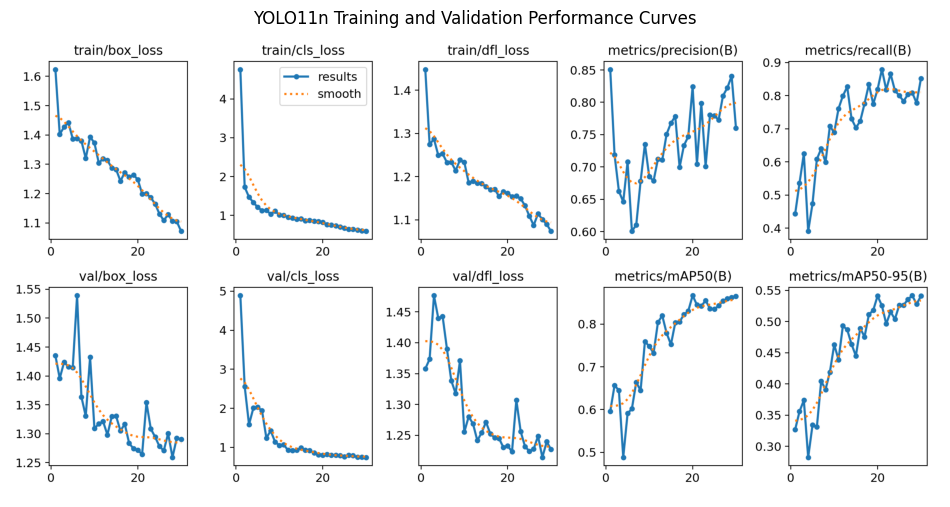

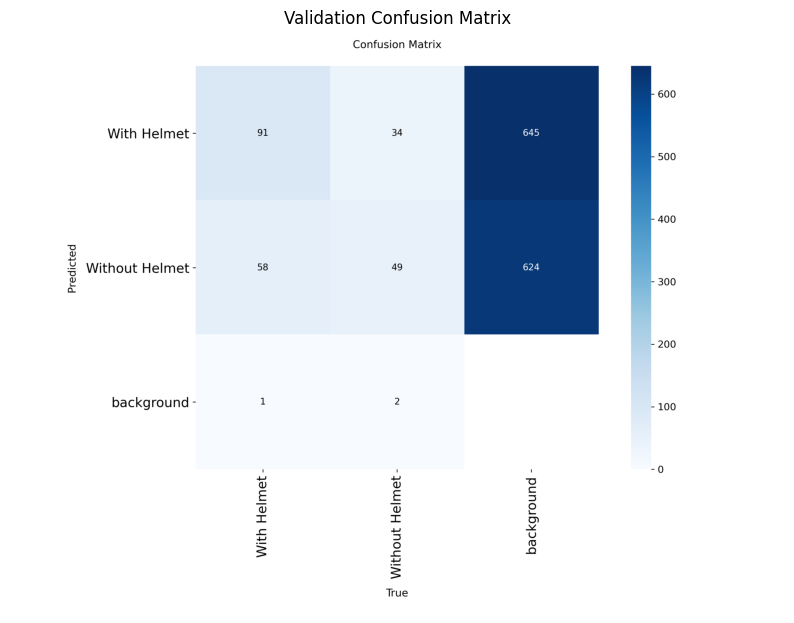

In [10]:
import cv2
import matplotlib.pyplot as plt
import glob

# 1. Plot Training/Validation Curves (results.png)
results_png = '/content/runs/detect/helmet_yolo11n/results.png'
if os.path.exists(results_png):
    plt.figure(figsize=(12, 8))
    img = cv2.imread(results_png)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.axis('off')
    plt.title('YOLO11n Training and Validation Performance Curves')
    plt.show()
else:
    print("Training performance graph results.png was not found.")

# 2. Plot Confusion Matrix
conf_matrix_png = '/content/runs/detect/val/confusion_matrix.png'
if os.path.exists(conf_matrix_png):
    plt.figure(figsize=(10, 8))
    img = cv2.imread(conf_matrix_png)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.axis('off')
    plt.title('Validation Confusion Matrix')
    plt.show()
else:
    print("Confusion matrix plot was not found in validation outputs.")

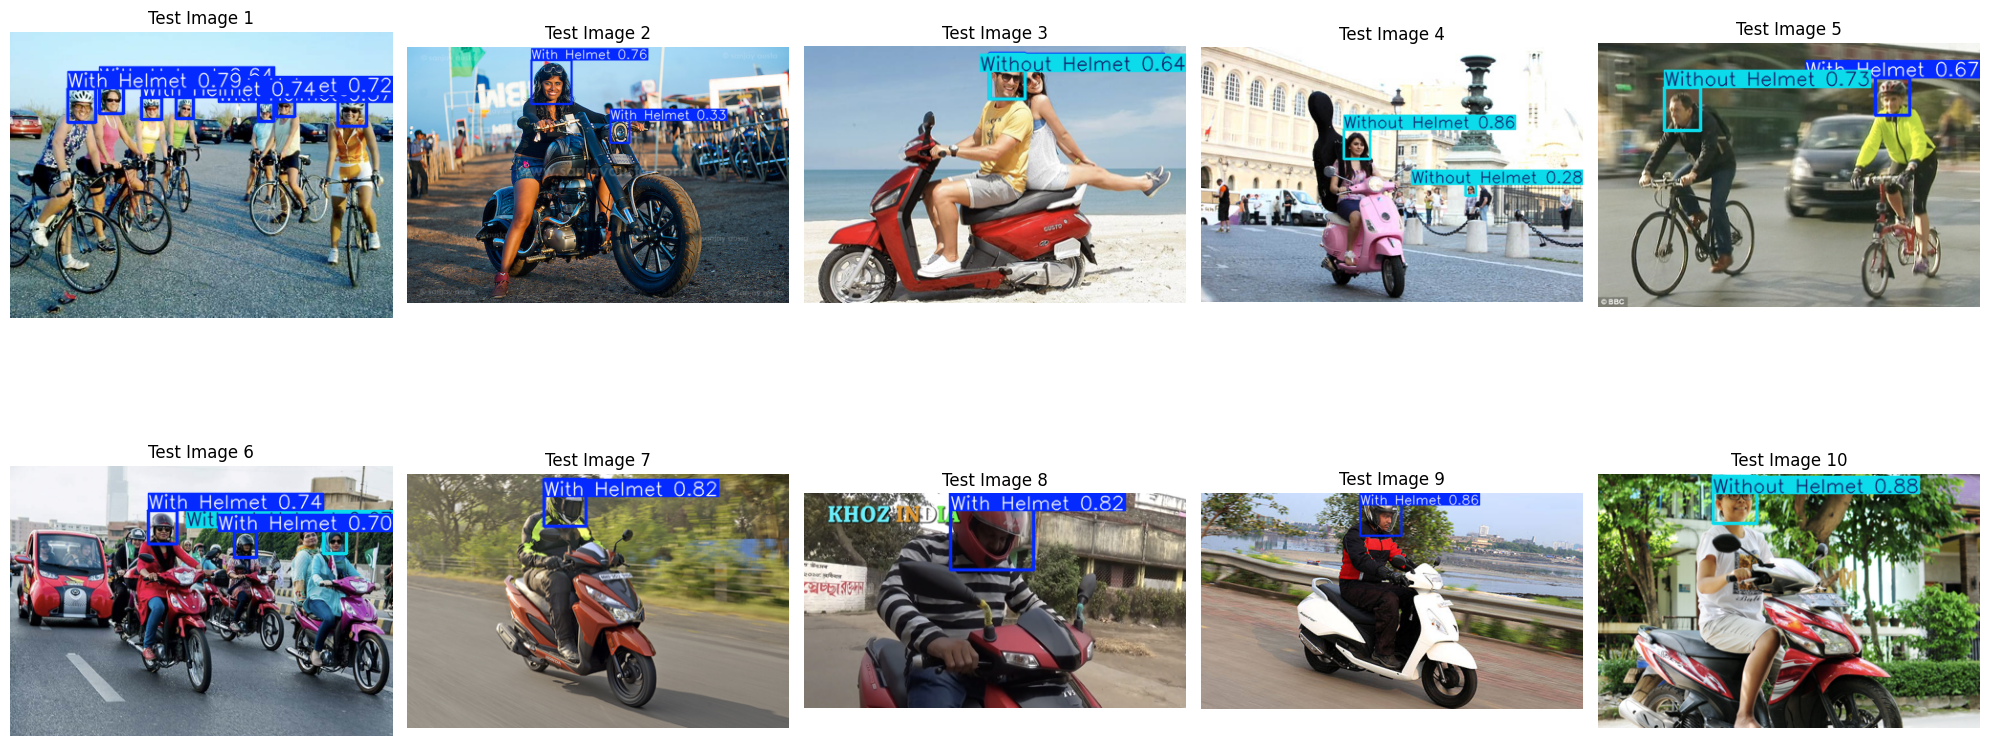

In [11]:
# 3. Render 10 Test Set Predictions with Bounding Boxes
test_images = sorted(glob.glob('/content/yolo_dataset/images/test/*.png'))[:10]

plt.figure(figsize=(20, 10))
for i, img_path in enumerate(test_images):
    res = model.predict(source=img_path, conf=0.25, verbose=False)[0]
    # Plot predictions
    img_bgr = res.plot()
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img_rgb)
    plt.title(f"Test Image {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Step 6: Interactive Image Upload for Real-Time Prediction
Run the cell below to upload an image from your local computer and check if individuals are wearing helmets or not.

In [12]:
from google.colab import files
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load the best model weights
model = YOLO('/content/runs/detect/helmet_yolo11n/weights/best.pt')

uploaded = files.upload()

for fn in uploaded.keys():
    print(f'Running prediction on uploaded file: "{fn}"')
    # Run inference
    results = model.predict(source=fn, conf=0.25, verbose=False)

    for res in results:
        # Plot predicted bounding boxes
        img_bgr = res.plot()
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 8))
        plt.imshow(img_rgb)
        plt.title(f"Inference Result: {fn}")
        plt.axis('off')
        plt.show()

KeyboardInterrupt: 

### Step 7: Export Trained Model to ONNX Format
Exporting model weights to Open Neural Network Exchange (ONNX) format allows integration with platforms like ONNX Runtime, OpenVINO, TensorRT, or browser-based runtimes.

In [ ]:
# Export the model
onnx_file_path = model.export(format='onnx')
print(f"SUCCESS: ONNX model successfully exported and saved at: {onnx_file_path}")

### Step 6: Image Upload and Real-Time Inference
Use the file uploader below to upload any image and visualize the helmet/no-helmet object detection predictions.

In [ ]:
from google.colab import files
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load the trained model
model = YOLO('/content/runs/detect/helmet_yolo11n/weights/best.pt')

uploaded = files.upload()

for fn in uploaded.keys():
    print(f'Running inference on: "{fn}"')
    # Run inference
    results = model.predict(source=fn, conf=0.25, verbose=False)

    # Display predictions
    for res in results:
        img_bgr = res.plot()
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 8))
        plt.imshow(img_rgb)
        plt.title(f"Predictions for {fn}")
        plt.axis('off')
        plt.show()

### Step 7: Export Model to ONNX Format
We will export the trained model (`best.pt`) to ONNX format to support external deployment and cross-platform integrations.

In [ ]:
# Export the model
onnx_path = model.export(format='onnx')
print(f"ONNX Model exported successfully to: {onnx_path}")